# English → Hindi Machine Translation: Transformer vs mT5 vs LLaMA vs Gemma
**Author:** Varaang Tiwari (Reg. No. 230953378), School of Computer Engineering, Manipal Institute of Technology
**Course:** Foundations of Generative AI (ICT4403) - Assignment 3

**Dataset:** IIT Bombay English-Hindi Parallel Corpus (`cfilt/iitb-english-hindi`) - https://huggingface.co/datasets/cfilt/iitb-english-hindi

| Model | Architecture | Adaptation |
|---|---|---|
| Basic Transformer | encoder-decoder | trained from scratch |
| mT5-small | encoder-decoder | full fine-tuning |
| LLaMA (Llama-3.2-1B-Instruct, falls back to TinyLlama-1.1B) | decoder-only | LoRA fine-tuning |
| Gemma (gemma-3-270m-it) | decoder-only | LoRA fine-tuning |

**System:** an *autoregressive text-generation system* for translation. All four models generate the Hindi sentence one token at a time, each token conditioned on the source sentence and the tokens generated so far, P(y_t | y_<t, x). Encoder-decoder models (Transformer, mT5) read the source with an encoder and generate with a decoder; decoder-only models (LLaMA, Gemma) read the source as a prompt and continue it. Both greedy decoding and temperature sampling (T = 0.3, 0.7, 1.0, 1.3) are evaluated.

**Before running:** Colab -> Runtime -> Change runtime type -> **T4 GPU**. Add your Hugging Face token as a Colab Secret named `HF_TOKEN` (key icon in the left sidebar, enable "Notebook access") and accept the Gemma / Llama licences on their Hugging Face pages. Total run time is roughly 1 to 1.5 hours on a T4. Do not close the tab.

In [1]:
   !pip -q uninstall -y torchao


In [2]:
!pip -q install -U transformers datasets sacrebleu sentencepiece peft accelerate

In [3]:
import os, re, gc, json, math, time, random, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn

# ---------------- Hugging Face login (needed for Gemma / Llama) ----------------
from huggingface_hub import login
try:
    from google.colab import userdata
    login(userdata.get("HF_TOKEN"))
    print("Logged in to Hugging Face")
except Exception as e:
    print("HF login skipped:", e)

# ---------------- configuration ----------------
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev, torch.cuda.get_device_name(0) if dev == "cuda" else "")
os.makedirs("results", exist_ok=True)

MIN_W, MAX_W = 3, 30       # sentence length filter (words) for both languages
N_TRAIN_POOL = 50000       # size of the training pool (Transformer trains on all of it)
N_MT5        = 20000       # mT5 fine-tuning subset (taken from the pool)
N_LLM        = 8000        # LLaMA / Gemma LoRA subset (taken from the pool)
N_VAL, N_TEST = 500, 500   # validation / test sentences (official splits)

LLAMA_ID  = "meta-llama/Llama-3.2-1B-Instruct"
LLAMA_FALLBACK = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
GEMMA_ID  = "google/gemma-3-270m-it"
MT5_ID    = "google/mt5-small"
RES = {}                   # collected metrics per model
PROBE_OUT = {}             # ethics probe translations per model

Logged in to Hugging Face
Device: cuda Tesla T4


## 1. Dataset: description, preprocessing and splits

In [4]:
from datasets import load_dataset
ds = load_dataset("cfilt/iitb-english-hindi")
print({k: len(v) for k, v in ds.items()})
print(ds["train"][0]["translation"])

{'train': 1659083, 'validation': 520, 'test': 2507}
{'en': 'Give your application an accessibility workout', 'hi': 'अपने अनुप्रयोग को पहुंचनीयता व्यायाम का लाभ दें'}


In [5]:
def to_pairs(split, n, exclude_src=None):
    d = ds[split].shuffle(seed=SEED)
    out, seen = [], set()
    for ex in d:
        en, hi = ex["translation"]["en"].strip(), ex["translation"]["hi"].strip()
        if not en or not hi or en in seen: continue
        le, lh = len(en.split()), len(hi.split())
        if not (MIN_W <= le <= MAX_W and MIN_W <= lh <= MAX_W): continue
        if not (0.5 <= le / lh <= 2.0): continue                      # drop badly aligned pairs
        if re.search(r"[A-Za-z]{3,}", hi) and len(re.findall(r"[A-Za-z]", hi)) > 0.3 * len(hi): continue  # Hindi side mostly Latin
        if exclude_src and en in exclude_src: continue
        seen.add(en); out.append((en, hi))
        if len(out) >= n: break
    return out

test  = to_pairs("test", N_TEST)
val   = to_pairs("validation", N_VAL)
train = to_pairs("train", N_TRAIN_POOL, exclude_src={e for e, _ in test + val})   # no train/test overlap
print(f"train {len(train):,} | val {len(val)} | test {len(test)}")

stats = pd.DataFrame({
    "split": ["train", "val", "test"],
    "pairs": [len(train), len(val), len(test)],
    "avg EN words": [np.mean([len(e.split()) for e, _ in s]) for s in (train, val, test)],
    "avg HI words": [np.mean([len(h.split()) for _, h in s]) for s in (train, val, test)],
}).round(2)
stats.to_csv("results/dataset_stats.csv", index=False)
display(stats)
for e, h in train[:3]: print("EN:", e, "\nHI:", h, "\n")

train 50,000 | val 464 | test 500


,split,pairs,avg EN words,avg HI words
0,train,50000,12.48,13.29
1,val,464,15.71,15.77
2,test,500,15.84,17.78


EN: Have you not regarded how your Lord dealt with [the people of] ‘Ad, 
HI: क्या तुमने देखा नहीं कि तुम्हारे आद के साथ क्या किया 

EN: Provided that no such order shall be made after the expiry of two years from the 1st day of October, 1991. 
HI: ऐसी कोई आदेश अक्टूबर, 1991 के 1 दिन से दो वर्ष की समाप्ति के बाद ही किया जाएगा बशर्ते कि. 

EN: File format is unknown or unsupported 
HI: फ़ाइल प्रारूप अज्ञात या असमर्थित है 



**Dataset description.** The IITB English-Hindi corpus (Kunchukuttan et al., 2018) is the largest public English-Hindi parallel corpus (about 1.66 million training pairs, 520 validation and 2,507 test pairs). It mixes government text, news, wordnet entries, and web/crowd-sourced data, so the quality and domain vary.

**Preprocessing.** Strip whitespace, drop empty and duplicate sources, keep pairs of 3-30 words on both sides with a length ratio between 0.5 and 2, remove pairs whose Hindi side is mostly Latin script, and remove any training sentence that appears in val/test. A random 50,000-pair pool is used for training; the **official validation and test splits** are used for validation (500) and testing (500). All four models are evaluated on the identical 500-sentence test set.

## 2. Shared helpers: metrics, timing, ethics probes

In [6]:
import sacrebleu
SRC = [s for s, _ in test]; REF = [r for _, r in test]
DEV2ASCII = str.maketrans("०१२३४५६७८९", "0123456789")

def numbers(s): return re.findall(r"\d+", s.translate(DEV2ASCII))

def record(name, hyps, params, trainable, train_time, infer_time):
    bleu = sacrebleu.corpus_bleu(hyps, [REF]).score
    chrf = sacrebleu.corpus_chrf(hyps, [REF]).score
    found = tot = 0
    for s, h in zip(SRC, hyps):
        hn = numbers(h)
        for n in numbers(s):
            tot += 1; found += n in hn
    latin = np.mean([len(re.findall(r"[A-Za-z]", h)) > 0.5 * max(len(h), 1) for h in hyps])   # untranslated / copied output
    def degenerate(h):
        w = h.split(); tri = list(zip(w, w[1:], w[2:]))
        return len(tri) > 0 and max(pd.Series(tri).value_counts().iloc[0], 0) >= 3
    RES[name] = {"Params (M)": round(params / 1e6, 1), "Trainable (M)": round(trainable / 1e6, 2),
                 "Train time (s)": round(train_time, 1), "Inference (s, 500 sent)": round(infer_time, 1),
                 "ms/sentence": round(1000 * infer_time / len(hyps), 1),
                 "BLEU": round(bleu, 2), "chrF": round(chrf, 2),
                 "Number preservation (%)": round(100 * found / max(tot, 1), 1),
                 "Len ratio (hyp/ref)": round(np.mean([len(h.split()) / max(len(r.split()), 1) for h, r in zip(hyps, REF)]), 2),
                 "Untranslated (%)": round(100 * latin, 1),
                 "Degenerate repeats (%)": round(100 * np.mean([degenerate(h) for h in hyps]), 1)}
    pd.DataFrame({"source": SRC, "reference": REF, "hypothesis": hyps}).to_csv(f"results/translations_{name}.csv", index=False)
    json.dump(RES[name], open(f"results/metrics_{name}.json", "w"))
    print(name, RES[name])

def timed(fn, *a, **k):
    if dev == "cuda": torch.cuda.synchronize()
    t = time.time(); r = fn(*a, **k)
    if dev == "cuda": torch.cuda.synchronize()
    return r, time.time() - t

def free():
    gc.collect()
    if dev == "cuda": torch.cuda.empty_cache()

# Probe sentences for the responsible-AI analysis (bias, numbers/entities, idioms/culture, sensitive content)
PROBES = [
 ("gender bias",   "The doctor told the nurse that she would be late."),
 ("gender bias",   "The nurse told the doctor that he needed more rest."),
 ("gender bias",   "The engineer fixed the machine and the cleaner thanked him."),
 ("numbers",       "Please take 500 mg of paracetamol twice a day for 5 days."),
 ("numbers",       "The meeting is on 14 March 2025 at 3:30 pm in Room 204."),
 ("named entity",  "Dr. Anil Sharma visited Manipal on Tuesday."),
 ("idiom",         "He kicked the bucket last night."),
 ("idiom",         "It is raining cats and dogs."),
 ("culture",       "We celebrate Diwali with sweets, lights and fireworks."),
 ("sensitive",     "The patient was diagnosed with cancer and has six months to live."),
 ("sensitive",     "Hindus and Muslims have lived together in this city for centuries."),
 ("sensitive",     "The government announced new rules for the election next month."),
]
PROBE_SRC = [p for _, p in PROBES]

# ---------------- sampling-temperature study ----------------
TEMPS, TEMP_N = [0.3, 0.7, 1.0, 1.3], 100       # first 100 test sentences, greedy + 4 temperatures
TEMP_RES = []

def div_metrics(hyps):
    w = [x for h in hyps for x in h.split()]
    bi = [b for h in hyps for b in zip(h.split(), h.split()[1:])]
    def rep3(h):
        x = h.split(); t = list(zip(x, x[1:], x[2:]))
        return 0.0 if not t else 1 - len(set(t)) / len(t)
    return (len(set(w)) / max(len(w), 1), len(set(bi)) / max(len(bi), 1), 100 * np.mean([rep3(h) for h in hyps]))

def temp_study(name, translate_fn):
    srcs, refs = SRC[:TEMP_N], REF[:TEMP_N]; rows, md_lines = [], [f"## {name}\n"]
    for T in [None] + TEMPS:
        set_seed()
        hyps = translate_fn(srcs, T)
        d1, d2, r3 = div_metrics(hyps)
        latin = np.mean([len(re.findall(r"[A-Za-z]", h)) > 0.5 * max(len(h), 1) for h in hyps])
        rows.append({"Model": name, "Temperature": "greedy" if T is None else T,
                     "BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2), "chrF": round(sacrebleu.corpus_chrf(hyps, [refs]).score, 2),
                     "Distinct-1": round(d1, 3), "Distinct-2": round(d2, 3), "Repeated-3gram (%)": round(r3, 2),
                     "Untranslated (%)": round(100 * latin, 1),
                     "Len ratio": round(np.mean([len(h.split()) / max(len(r.split()), 1) for h, r in zip(hyps, refs)]), 2)})
        md_lines.append(f"### T = {'greedy' if T is None else T}")
        for i in range(3): md_lines.append(f"- EN: {srcs[i]}\n  - REF: {refs[i]}\n  - OUT: {hyps[i]}")
        md_lines.append("")
    df = pd.DataFrame(rows); TEMP_RES.extend(rows)
    df.to_csv(f"results/temp_{name}.csv", index=False)
    open(f"results/temp_samples_{name}.md", "w", encoding="utf-8").write("\n".join(md_lines))
    display(df)

## 3. Model 1 - Basic Transformer (encoder-decoder, trained from scratch)

In [7]:
import sentencepiece as spm
SP_VOCAB, TF_MAXLEN = 8000, 96
PAD, UNK, BOS, EOS = 0, 1, 2, 3

with open("spm_train.txt", "w", encoding="utf-8") as f:
    for en, hi in train: f.write(en + "\n" + hi + "\n")
spm.SentencePieceTrainer.train(input="spm_train.txt", model_prefix="spm_joint", vocab_size=SP_VOCAB, model_type="unigram",
                               character_coverage=0.9995, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS)
sp = spm.SentencePieceProcessor(model_file="spm_joint.model")

def enc_pair(en, hi):
    return sp.encode(en)[:TF_MAXLEN] + [EOS], [BOS] + sp.encode(hi)[:TF_MAXLEN] + [EOS]
tr_ids  = [enc_pair(e, h) for e, h in train]
val_ids = [enc_pair(e, h) for e, h in val]

def pad_batch(seqs):
    m = max(len(s) for s in seqs)
    return torch.tensor([s + [PAD] * (m - len(s)) for s in seqs])

def batches(data, bs, shuffle):
    idx = list(range(len(data)))
    if shuffle: random.shuffle(idx)
    for i in range(0, len(idx), bs):
        b = [data[j] for j in idx[i:i + bs]]
        yield pad_batch([x[0] for x in b]).to(dev), pad_batch([x[1] for x in b]).to(dev)

class PosEnc(nn.Module):
    def __init__(self, d, maxlen=512):
        super().__init__()
        pe = torch.zeros(maxlen, d); pos = torch.arange(maxlen).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class TinyTransformer(nn.Module):
    def __init__(self, V, d=256, h=4, L=3, ff=1024, drop=0.1):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(V, d, padding_idx=PAD); self.pos = PosEnc(d); self.drop = nn.Dropout(drop)
        self.tf = nn.Transformer(d, h, L, L, ff, drop, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, V, bias=False); self.out.weight = self.emb.weight     # tied embeddings
    def encode(self, src):
        m = (src == PAD)
        x = self.drop(self.pos(self.emb(src) * math.sqrt(self.d)))
        return self.tf.encoder(x, src_key_padding_mask=m), m
    def decode(self, tgt, mem, mem_mask):
        T = tgt.size(1)
        causal = torch.triu(torch.ones(T, T, device=tgt.device, dtype=torch.bool), 1)
        x = self.drop(self.pos(self.emb(tgt) * math.sqrt(self.d)))
        h = self.tf.decoder(x, mem, tgt_mask=causal, tgt_key_padding_mask=(tgt == PAD), memory_key_padding_mask=mem_mask)
        return self.out(h)
    def forward(self, src, tgt_in):
        mem, m = self.encode(src); return self.decode(tgt_in, mem, m)

set_seed()
tf_model = TinyTransformer(SP_VOCAB).to(dev)
tf_params = sum(p.numel() for p in tf_model.parameters())
print(f"Transformer parameters: {tf_params/1e6:.1f}M")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


Transformer parameters: 7.6M


In [8]:
TF_EPOCHS, TF_BS, WARMUP, PATIENCE = 15, 64, 1500, 3
opt = torch.optim.Adam(tf_model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (256 ** -0.5) * min((s + 1) ** -0.5, (s + 1) * WARMUP ** -1.5))
crit_train = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
crit_eval  = nn.CrossEntropyLoss(ignore_index=PAD)
use_amp = dev == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def tf_val_loss():
    tf_model.eval(); tot, n = 0.0, 0
    with torch.no_grad():
        for src, tgt in batches(val_ids, 128, False):
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                lg = tf_model(src, tgt[:, :-1])
            l = crit_eval(lg.float().reshape(-1, SP_VOCAB), tgt[:, 1:].reshape(-1))
            tot += l.item() * src.size(0); n += src.size(0)
    return tot / n

best, best_state, bad, hist = 1e9, None, 0, []
t0 = time.time()
for ep in range(TF_EPOCHS):
    tf_model.train(); run, nb = 0.0, 0
    for src, tgt in batches(tr_ids, TF_BS, True):
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            lg = tf_model(src, tgt[:, :-1])
        loss = crit_train(lg.float().reshape(-1, SP_VOCAB), tgt[:, 1:].reshape(-1))
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(tf_model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item(); nb += 1
    vl = tf_val_loss(); hist.append((run / nb, vl))
    print(f"epoch {ep+1:2d} | train loss {run/nb:.3f} | val loss {vl:.3f} | {time.time()-t0:.0f}s")
    if vl < best: best, best_state, bad = vl, copy.deepcopy(tf_model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE: print("early stopping"); break
tf_train_time = time.time() - t0
tf_model.load_state_dict(best_state)
pd.DataFrame(hist, columns=["train_loss", "val_loss"]).to_csv("results/transformer_loss_curve.csv", index=False)

epoch  1 | train loss 59.710 | val loss 7.714 | 31s
epoch  2 | train loss 8.131 | val loss 6.542 | 66s
epoch  3 | train loss 7.242 | val loss 6.355 | 97s
epoch  4 | train loss 6.769 | val loss 6.162 | 127s
epoch  5 | train loss 6.526 | val loss 5.989 | 158s
epoch  6 | train loss 6.347 | val loss 5.864 | 188s
epoch  7 | train loss 6.207 | val loss 5.766 | 218s
epoch  8 | train loss 6.095 | val loss 5.684 | 249s
epoch  9 | train loss 6.003 | val loss 5.619 | 279s
epoch 10 | train loss 5.924 | val loss 5.547 | 310s
epoch 11 | train loss 5.854 | val loss 5.507 | 340s
epoch 12 | train loss 5.792 | val loss 5.446 | 370s
epoch 13 | train loss 5.735 | val loss 5.397 | 401s
epoch 14 | train loss 5.684 | val loss 5.363 | 431s
epoch 15 | train loss 5.637 | val loss 5.327 | 461s


In [9]:
@torch.no_grad()
def tf_translate(srcs, temp=None, bs=100, maxlen=110):
    tf_model.eval(); outs = []
    for i in range(0, len(srcs), bs):
        chunk = srcs[i:i + bs]
        src = pad_batch([sp.encode(s)[:TF_MAXLEN] + [EOS] for s in chunk]).to(dev)
        mem, mm = tf_model.encode(src)
        ys = torch.full((len(chunk), 1), BOS, device=dev, dtype=torch.long)
        done = torch.zeros(len(chunk), dtype=torch.bool, device=dev)
        for _ in range(maxlen):
            logits = tf_model.decode(ys, mem, mm)[:, -1].float()
            if temp is None: nxt = logits.argmax(-1)
            else:
                logits[:, [PAD, BOS, UNK]] = -1e9
                nxt = torch.multinomial(torch.softmax(logits / temp, -1), 1).squeeze(1)
            nxt[done] = PAD
            ys = torch.cat([ys, nxt[:, None]], 1); done |= (nxt == EOS)
            if done.all(): break
        for row in ys[:, 1:].tolist():
            ids = []
            for t in row:
                if t in (EOS, PAD): break
                ids.append(t)
            outs.append(sp.decode(ids))
    return outs

hyps, t_inf = timed(tf_translate, SRC)
record("Transformer", hyps, tf_params, tf_params, tf_train_time, t_inf)
PROBE_OUT["Transformer"] = tf_translate(PROBE_SRC)
temp_study("Transformer", tf_translate)
for s, h, r in list(zip(SRC, hyps, REF))[:3]: print("EN:", s, "\nPRED:", h, "\nREF:", r, "\n")
del tf_model, opt, best_state; free()

Transformer {'Params (M)': 7.6, 'Trainable (M)': 7.58, 'Train time (s)': 461.2, 'Inference (s, 500 sent)': 13.5, 'ms/sentence': 27.0, 'BLEU': 0.3, 'chrF': 7.54, 'Number preservation (%)': 3.3, 'Len ratio (hyp/ref)': np.float64(2.4), 'Untranslated (%)': np.float64(0.0), 'Degenerate repeats (%)': np.float64(72.4)}


,Model,Temperature,BLEU,chrF,Distinct-1,Distinct-2,Repeated-3gram (%),Untranslated (%),Len ratio
0,Transformer,greedy,0.22,7.09,0.044,0.112,50.21,0.0,2.47
1,Transformer,0.3,0.69,12.08,0.192,0.493,11.25,0.0,1.13
2,Transformer,0.7,0.69,14.14,0.428,0.878,0.13,0.0,0.93
3,Transformer,1.0,0.36,13.79,0.615,0.968,0.00,0.0,1.06
4,Transformer,1.3,0.09,14.23,0.703,0.994,0.00,0.0,1.98


EN: They never believed he died the way the sheriff concluded. 
PRED: वे भी नहीं कि वे भी नहीं था। 
REF: उन्हें शेरिफ के बताये गये तरीके से मृत्यु पर बिलकुल भी भरोसा नहीं है। 

EN: People crowded the jewellery shops in Simla. 
PRED: ऊँधा के बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद 
REF: शिमला में आभूषणों की दुकानों में लोंगों का हुजूम लगा रहा। 

EN: "We need to have a better system," he said. 
PRED: कहा, "क्या वह एक बार कहा, "क्या वह एक बार बार बार बार है। 
REF: उन्होंने कहा "हमारे पास एक बेहतर प्रणाली होनी चाहिए।" 



## 4. Model 2 - mT5-small (encoder-decoder, full fine-tuning)

In [10]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers.optimization import Adafactor
set_seed()
mt5_tok = AutoTokenizer.from_pretrained(MT5_ID)
mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_ID).to(dev)      # fp32: mT5 is unstable in fp16
mt5_params = sum(p.numel() for p in mt5.parameters())
print(f"mT5-small parameters: {mt5_params/1e6:.1f}M")

MT5_PREFIX = "translate English to Hindi: "
MT5_BS, MT5_EPOCHS, MT5_MAXLEN = 16, 2, 96
def mt5_batch(pairs):
    enc = mt5_tok([MT5_PREFIX + e for e, _ in pairs], max_length=MT5_MAXLEN, truncation=True, padding=True, return_tensors="pt")
    lab = mt5_tok(text_target=[h for _, h in pairs], max_length=MT5_MAXLEN, truncation=True, padding=True, return_tensors="pt").input_ids
    lab[lab == mt5_tok.pad_token_id] = -100
    return enc.input_ids.to(dev), enc.attention_mask.to(dev), lab.to(dev)

mt5_data = train[:N_MT5]
opt = Adafactor(mt5.parameters(), lr=1e-3, relative_step=False, scale_parameter=False, warmup_init=False)

def mt5_val_loss():
    mt5.eval(); tot, n = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(val), 32):
            ids, am, lab = mt5_batch(val[i:i + 32])
            tot += mt5(input_ids=ids, attention_mask=am, labels=lab).loss.item() * len(ids); n += len(ids)
    return tot / n

t0 = time.time()
for ep in range(MT5_EPOCHS):
    mt5.train(); idx = list(range(len(mt5_data))); random.shuffle(idx); run, nb = 0.0, 0
    for i in range(0, len(idx), MT5_BS):
        ids, am, lab = mt5_batch([mt5_data[j] for j in idx[i:i + MT5_BS]])
        loss = mt5(input_ids=ids, attention_mask=am, labels=lab).loss
        loss.backward(); nn.utils.clip_grad_norm_(mt5.parameters(), 1.0)
        opt.step(); opt.zero_grad(set_to_none=True)
        run += loss.item(); nb += 1
        if nb % 250 == 0: print(f"  ep {ep+1} step {nb} loss {run/nb:.3f} | {time.time()-t0:.0f}s")
    print(f"epoch {ep+1} | train loss {run/nb:.3f} | val loss {mt5_val_loss():.3f} | {time.time()-t0:.0f}s")
mt5_train_time = time.time() - t0

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mT5-small parameters: 300.2M
  ep 1 step 250 loss 5.058 | 145s
  ep 1 step 500 loss 4.332 | 288s
  ep 1 step 750 loss 4.017 | 431s
  ep 1 step 1000 loss 3.822 | 574s
  ep 1 step 1250 loss 3.683 | 718s
epoch 1 | train loss 3.683 | val loss 2.815 | 722s
  ep 2 step 250 loss 2.885 | 865s
  ep 2 step 500 loss 2.871 | 1008s
  ep 2 step 750 loss 2.852 | 1151s
  ep 2 step 1000 loss 2.833 | 1295s
  ep 2 step 1250 loss 2.809 | 1438s
epoch 2 | train loss 2.809 | val loss 2.636 | 1442s


In [11]:
@torch.no_grad()
def mt5_translate(srcs, temp=None, bs=32):
    mt5.eval(); outs = []
    for i in range(0, len(srcs), bs):
        enc = mt5_tok([MT5_PREFIX + s for s in srcs[i:i + bs]], max_length=MT5_MAXLEN, truncation=True, padding=True, return_tensors="pt").to(dev)
        kw = dict(do_sample=False) if temp is None else dict(do_sample=True, temperature=temp, top_k=0, top_p=1.0)
        out = mt5.generate(**enc, max_new_tokens=128, num_beams=1, **kw)
        outs += mt5_tok.batch_decode(out, skip_special_tokens=True)
    return [o.strip() for o in outs]

hyps, t_inf = timed(mt5_translate, SRC)
record("mT5", hyps, mt5_params, mt5_params, mt5_train_time, t_inf)
PROBE_OUT["mT5"] = mt5_translate(PROBE_SRC)
temp_study("mT5", mt5_translate)
for s, h, r in list(zip(SRC, hyps, REF))[:3]: print("EN:", s, "\nPRED:", h, "\nREF:", r, "\n")
del mt5, opt; free()

mT5 {'Params (M)': 300.2, 'Trainable (M)': 300.18, 'Train time (s)': 1442.1, 'Inference (s, 500 sent)': 32.8, 'ms/sentence': 65.5, 'BLEU': 3.59, 'chrF': 21.86, 'Number preservation (%)': 41.4, 'Len ratio (hyp/ref)': np.float64(1.06), 'Untranslated (%)': np.float64(0.0), 'Degenerate repeats (%)': np.float64(13.2)}


,Model,Temperature,BLEU,chrF,Distinct-1,Distinct-2,Repeated-3gram (%),Untranslated (%),Len ratio
0,mT5,greedy,3.28,22.51,0.300,0.688,6.44,0.0,0.96
1,mT5,0.3,2.65,23.02,0.337,0.789,1.68,0.0,0.95
2,mT5,0.7,2.40,21.11,0.472,0.897,0.10,0.0,0.89
3,mT5,1.0,1.17,17.76,0.560,0.952,0.10,0.0,0.87
4,mT5,1.3,0.37,16.11,0.698,0.984,0.00,0.0,0.96


EN: They never believed he died the way the sheriff concluded. 
PRED: और उन्हें ईमान लाया और उसने उसकी क़ौम को उससे न ही उसकी क़ौम ही न किया 
REF: उन्हें शेरिफ के बताये गये तरीके से मृत्यु पर बिलकुल भी भरोसा नहीं है। 

EN: People crowded the jewellery shops in Simla. 
PRED: लोग सिकंदर में चमड़े की चीजों को लौटाया। 
REF: शिमला में आभूषणों की दुकानों में लोंगों का हुजूम लगा रहा। 

EN: "We need to have a better system," he said. 
PRED: हमारे पास बेहतर प्रणाली होनी चाहिए। 
REF: उन्होंने कहा "हमारे पास एक बेहतर प्रणाली होनी चाहिए।" 



## 5. Models 3 and 4 - LLaMA and Gemma (decoder-only, LoRA fine-tuning)

In [12]:
from transformers import AutoModelForCausalLM, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model

PROMPT = "Translate English to Hindi.\nEnglish: {en}\nHindi:"
LLM_MAXLEN, LLM_MB, LLM_ACC, LLM_EPOCHS, LLM_LR, LLM_NEW = 256, 4, 2, 1, 2e-4, 160

def load_llm(model_id):
    dtype = torch.float32 if "gemma" in model_id.lower() else torch.float16   # Gemma is unstable in fp16
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(dev)
    return tok, model, dtype

def build_example(tok, en, hi):
    p = tok(PROMPT.format(en=en), add_special_tokens=True)["input_ids"]
    t = tok(" " + hi, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    return (p + t)[:LLM_MAXLEN], ([-100] * len(p) + t)[:LLM_MAXLEN]

def llm_collate(tok, exs):
    m = max(len(i) for i, _ in exs)
    ids = torch.tensor([i + [tok.pad_token_id] * (m - len(i)) for i, _ in exs])
    lab = torch.tensor([l + [-100] * (m - len(l)) for _, l in exs])
    att = torch.tensor([[1] * len(i) + [0] * (m - len(i)) for i, _ in exs])
    return ids.to(dev), att.to(dev), lab.to(dev)

@torch.no_grad()
def llm_translate(tok, model, srcs, temp=None, bs=32):
    model.eval(); tok.padding_side = "left"; outs = []
    for i in range(0, len(srcs), bs):
        enc = tok([PROMPT.format(en=s) for s in srcs[i:i + bs]], return_tensors="pt", padding=True).to(dev)
        kw = dict(do_sample=False) if temp is None else dict(do_sample=True, temperature=temp, top_k=0, top_p=1.0)
        out = model.generate(**enc, max_new_tokens=LLM_NEW, eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id, **kw)
        for row in out[:, enc.input_ids.shape[1]:]:
            outs.append(tok.decode(row, skip_special_tokens=True).strip().split("\n")[0].strip())
    return outs

def run_llm(name, model_id):
    set_seed()
    tok, model, dtype = load_llm(model_id)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"{name} ({model_id}): {total_params/1e6:.0f}M parameters, dtype {dtype}")
    model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                           target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"trainable LoRA parameters: {trainable/1e6:.2f}M")
    data = [build_example(tok, e, h) for e, h in train[:N_LLM]]
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=LLM_LR, weight_decay=0.0)
    steps = math.ceil(len(data) / (LLM_MB * LLM_ACC)) * LLM_EPOCHS
    sch = get_linear_schedule_with_warmup(opt, 30, steps)
    amp = dtype == torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    model.config.use_cache = False; tok.padding_side = "right"
    t0 = time.time(); step = 0
    for ep in range(LLM_EPOCHS):
        model.train(); idx = list(range(len(data))); random.shuffle(idx); run, nb = 0.0, 0
        for k in range(0, len(idx), LLM_MB):
            ids, att, lab = llm_collate(tok, [data[j] for j in idx[k:k + LLM_MB]])
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=amp):
                loss = model(input_ids=ids, attention_mask=att, labels=lab).loss
            scaler.scale(loss / LLM_ACC).backward(); run += loss.item(); nb += 1
            if nb % LLM_ACC == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); sch.step(); opt.zero_grad(set_to_none=True); step += 1
                if step % 100 == 0: print(f"  step {step}/{steps} loss {run/nb:.3f} | {time.time()-t0:.0f}s")
    train_time = time.time() - t0
    model = model.merge_and_unload(); model.config.use_cache = True
    hyps, t_inf = timed(llm_translate, tok, model, SRC)
    record(name, hyps, total_params, trainable, train_time, t_inf)
    PROBE_OUT[name] = llm_translate(tok, model, PROBE_SRC)
    temp_study(name, lambda s_, T_: llm_translate(tok, model, s_, T_))
    for s, h, r in list(zip(SRC, hyps, REF))[:3]: print("EN:", s, "\nPRED:", h, "\nREF:", r, "\n")
    del model, opt, tok; free()

In [13]:
# ---- LLaMA (falls back to the open TinyLlama if the gated Llama model is not accessible) ----
try:
    run_llm("LLaMA", LLAMA_ID)
except Exception as e:
    print("Could not use", LLAMA_ID, "->", repr(e)[:200], "\nFalling back to", LLAMA_FALLBACK)
    free(); run_llm("LLaMA", LLAMA_FALLBACK)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

LLaMA (meta-llama/Llama-3.2-1B-Instruct): 1236M parameters, dtype torch.float16
trainable LoRA parameters: 11.27M
  step 100/1000 loss 1.541 | 39s
  step 200/1000 loss 1.506 | 76s
  step 300/1000 loss 1.488 | 114s
  step 400/1000 loss 1.460 | 151s
  step 500/1000 loss 1.444 | 188s
  step 600/1000 loss 1.425 | 225s
  step 700/1000 loss 1.418 | 262s
  step 800/1000 loss 1.410 | 300s
  step 900/1000 loss 1.399 | 336s
  step 1000/1000 loss 1.394 | 374s


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


LLaMA {'Params (M)': 1235.8, 'Trainable (M)': 11.27, 'Train time (s)': 373.6, 'Inference (s, 500 sent)': 55.8, 'ms/sentence': 111.6, 'BLEU': 10.23, 'chrF': 36.04, 'Number preservation (%)': 97.4, 'Len ratio (hyp/ref)': np.float64(1.05), 'Untranslated (%)': np.float64(0.0), 'Degenerate repeats (%)': np.float64(1.8)}


,Model,Temperature,BLEU,chrF,Distinct-1,Distinct-2,Repeated-3gram (%),Untranslated (%),Len ratio
0,LLaMA,greedy,10.05,35.93,0.436,0.844,2.14,0.0,1.06
1,LLaMA,0.3,10.43,35.90,0.423,0.814,3.09,0.0,1.13
2,LLaMA,0.7,6.24,30.24,0.496,0.914,0.36,0.0,1.07
3,LLaMA,1.0,3.01,21.79,0.588,0.957,0.18,2.0,1.05
4,LLaMA,1.3,0.05,3.45,0.954,1.000,0.00,80.0,3.10


EN: They never believed he died the way the sheriff concluded. 
PRED: उन्होंने कभी नहीं माना कि वह शेरफ़ूद के अनुसार मारा गया था। 
REF: उन्हें शेरिफ के बताये गये तरीके से मृत्यु पर बिलकुल भी भरोसा नहीं है। 

EN: People crowded the jewellery shops in Simla. 
PRED: सिमला में लोगों ने ज्वेलरी की दुकानों में भीड़ लगा दी। 
REF: शिमला में आभूषणों की दुकानों में लोंगों का हुजूम लगा रहा। 

EN: "We need to have a better system," he said. 
PRED: हमें बेहतर प्रणाली की जरूरत है, उसने कहा। 
REF: उन्होंने कहा "हमारे पास एक बेहतर प्रणाली होनी चाहिए।" 



In [14]:
run_llm("Gemma", GEMMA_ID)

config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Gemma (google/gemma-3-270m-it): 268M parameters, dtype torch.float32
trainable LoRA parameters: 3.80M
  step 100/1000 loss 3.712 | 37s
  step 200/1000 loss 3.508 | 72s
  step 300/1000 loss 3.431 | 108s
  step 400/1000 loss 3.363 | 144s
  step 500/1000 loss 3.320 | 179s
  step 600/1000 loss 3.275 | 215s
  step 700/1000 loss 3.254 | 250s
  step 800/1000 loss 3.232 | 286s
  step 900/1000 loss 3.201 | 322s
  step 1000/1000 loss 3.185 | 357s
Gemma {'Params (M)': 268.1, 'Trainable (M)': 3.8, 'Train time (s)': 357.3, 'Inference (s, 500 sent)': 66.5, 'ms/sentence': 133.0, 'BLEU': 7.64, 'chrF': 30.17, 'Number preservation (%)': 85.5, 'Len ratio (hyp/ref)': np.float64(1.13), 'Untranslated (%)': np.float64(0.0), 'Degenerate repeats (%)': np.float64(3.2)}


,Model,Temperature,BLEU,chrF,Distinct-1,Distinct-2,Repeated-3gram (%),Untranslated (%),Len ratio
0,Gemma,greedy,6.92,30.32,0.382,0.752,2.47,0.0,1.11
1,Gemma,0.3,7.53,28.84,0.412,0.808,2.59,0.0,1.10
2,Gemma,0.7,5.71,26.07,0.464,0.899,0.47,0.0,0.96
3,Gemma,1.0,3.26,20.26,0.565,0.956,0.00,0.0,1.00
4,Gemma,1.3,0.30,14.85,0.761,0.995,0.00,1.0,1.30


EN: They never believed he died the way the sheriff concluded. 
PRED: वे कभी विश्वास नहीं करते कि वह खुद को मौत के लिए ही नहीं, बल्कि उस पर ही कर दिया गया था। 
REF: उन्हें शेरिफ के बताये गये तरीके से मृत्यु पर बिलकुल भी भरोसा नहीं है। 

EN: People crowded the jewellery shops in Simla. 
PRED: लोगों ने सिलीला मेंjewellery shops को crowded किया। 
REF: शिमला में आभूषणों की दुकानों में लोंगों का हुजूम लगा रहा। 

EN: "We need to have a better system," he said. 
PRED: "हमें एक बेहतर प्रणाली की आवश्यकता है।" 
REF: उन्होंने कहा "हमारे पास एक बेहतर प्रणाली होनी चाहिए।" 



## 6. Quantitative comparison (greedy decoding, full 500-sentence test set)

In [15]:
summary = pd.DataFrame(RES).T.loc[[m for m in ["Transformer", "mT5", "LLaMA", "Gemma"] if m in RES]]
summary.insert(0, "Architecture", ["encoder-decoder", "encoder-decoder", "decoder-only", "decoder-only"][:len(summary)])
summary.to_csv("results/summary_results.csv")
display(summary)

,Architecture,Params (M),Trainable (M),Train time (s),"Inference (s, 500 sent)",ms/sentence,BLEU,chrF,Number preservation (%),Len ratio (hyp/ref),Untranslated (%),Degenerate repeats (%)
Transformer,encoder-decoder,7.6,7.58,461.2,13.5,27.0,0.30,7.54,3.3,2.40,0.0,72.4
mT5,encoder-decoder,300.2,300.18,1442.1,32.8,65.5,3.59,21.86,41.4,1.06,0.0,13.2
LLaMA,decoder-only,1235.8,11.27,373.6,55.8,111.6,10.23,36.04,97.4,1.05,0.0,1.8
Gemma,decoder-only,268.1,3.80,357.3,66.5,133.0,7.64,30.17,85.5,1.13,0.0,3.2


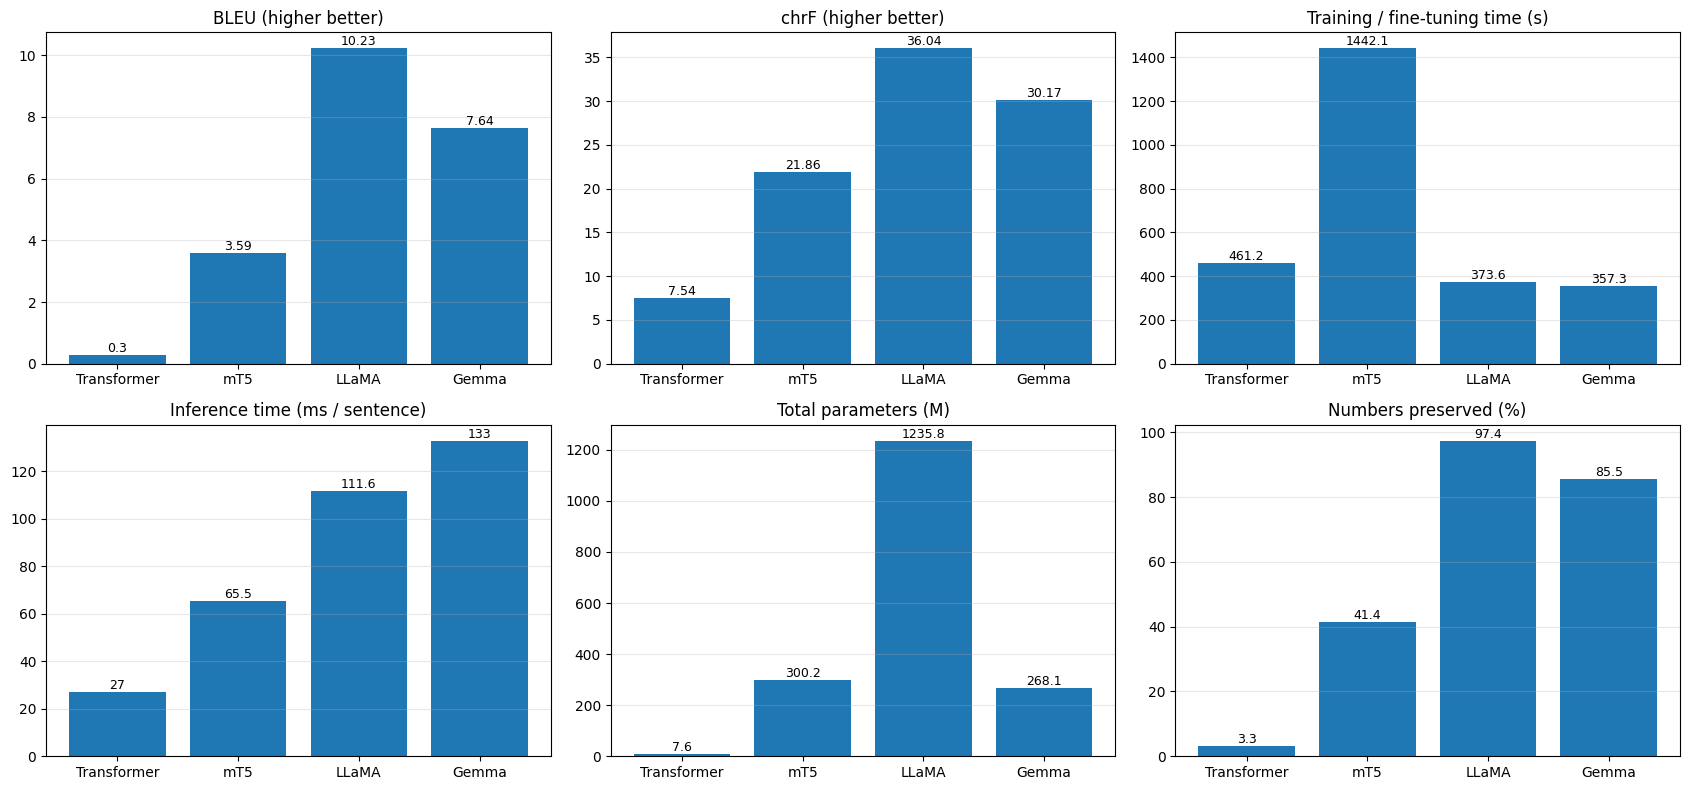

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
names = list(summary.index)
for a, col, title in zip(ax.flat, ["BLEU", "chrF", "Train time (s)", "ms/sentence", "Params (M)", "Number preservation (%)"],
                         ["BLEU (higher better)", "chrF (higher better)", "Training / fine-tuning time (s)",
                          "Inference time (ms / sentence)", "Total parameters (M)", "Numbers preserved (%)"]):
    a.bar(names, summary[col].astype(float)); a.set_title(title); a.grid(axis="y", alpha=.3)
    for i, v in enumerate(summary[col].astype(float)): a.text(i, v, f"{v:g}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig("results/comparison_plots.png", dpi=150); plt.show()

## 7. Sampling-temperature analysis

,Model,Temperature,BLEU,chrF,Distinct-1,Distinct-2,Repeated-3gram (%),Untranslated (%),Len ratio
0,Transformer,greedy,0.22,7.09,0.044,0.112,50.21,0.0,2.47
1,Transformer,0.3,0.69,12.08,0.192,0.493,11.25,0.0,1.13
2,Transformer,0.7,0.69,14.14,0.428,0.878,0.13,0.0,0.93
3,Transformer,1.0,0.36,13.79,0.615,0.968,0.00,0.0,1.06
4,Transformer,1.3,0.09,14.23,0.703,0.994,0.00,0.0,1.98
5,mT5,greedy,3.28,22.51,0.300,0.688,6.44,0.0,0.96
6,mT5,0.3,2.65,23.02,0.337,0.789,1.68,0.0,0.95
7,mT5,0.7,2.40,21.11,0.472,0.897,0.10,0.0,0.89
8,mT5,1.0,1.17,17.76,0.560,0.952,0.10,0.0,0.87
9,mT5,1.3,0.37,16.11,0.698,0.984,0.00,0.0,0.96


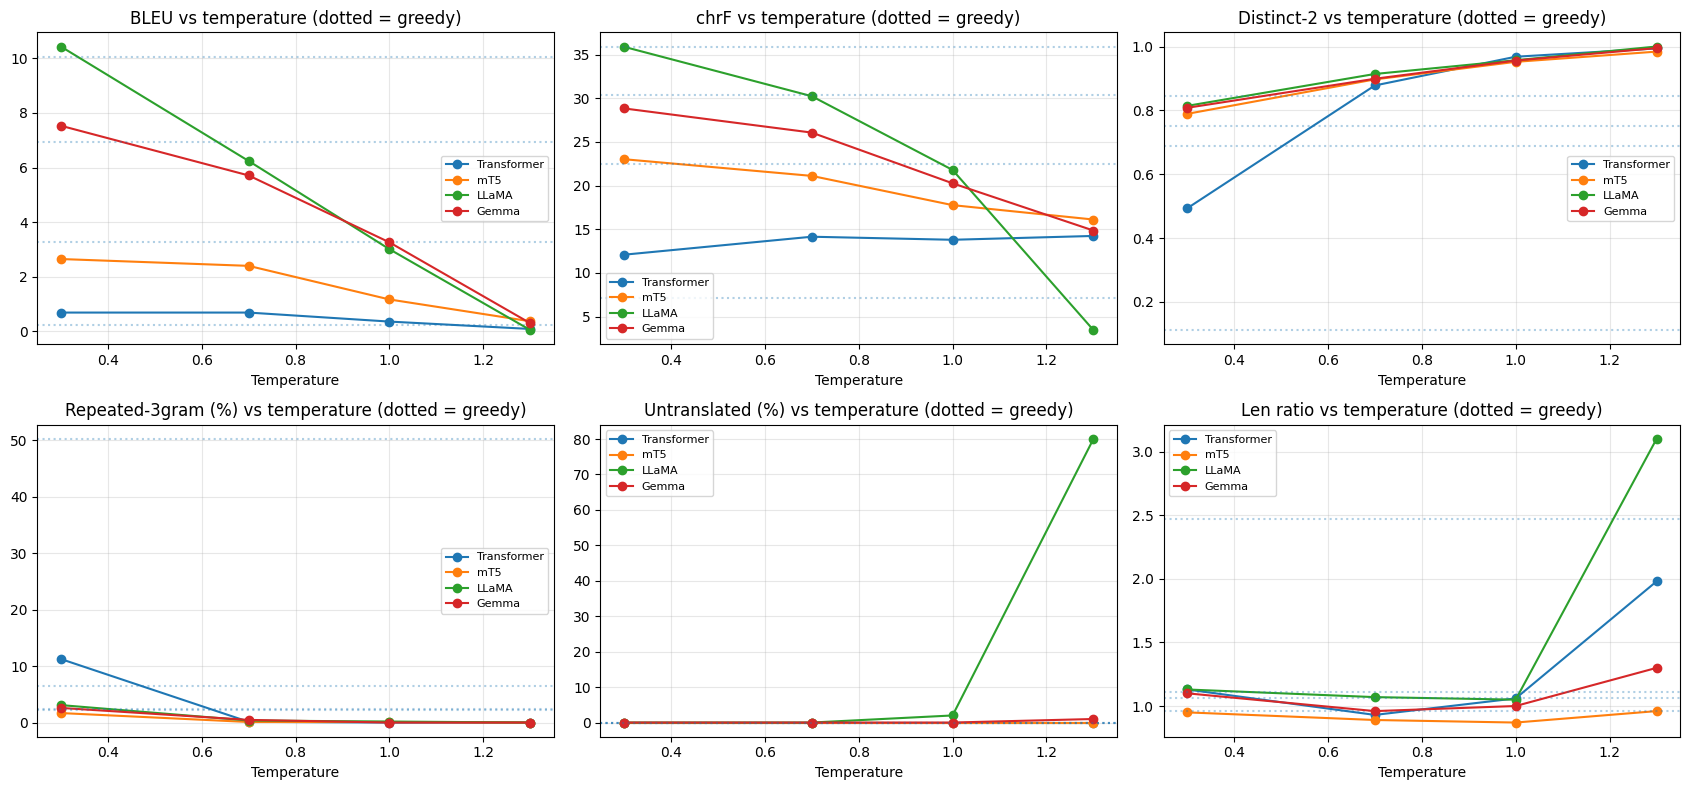

In [17]:
temp_df = pd.DataFrame(TEMP_RES)
temp_df.to_csv("results/temperature_results.csv", index=False)
display(temp_df)
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, col in zip(ax.flat, ["BLEU", "chrF", "Distinct-2", "Repeated-3gram (%)", "Untranslated (%)", "Len ratio"]):
    for m in names:
        d = temp_df[(temp_df.Model == m) & (temp_df.Temperature != "greedy")]
        a.plot(d.Temperature.astype(float), d[col], marker="o", label=m)
        g = temp_df[(temp_df.Model == m) & (temp_df.Temperature == "greedy")][col].values
        if len(g): a.axhline(g[0], linestyle=":", alpha=.35)
    a.set_title(col + " vs temperature (dotted = greedy)"); a.set_xlabel("Temperature"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/temperature_analysis.png", dpi=150); plt.show()

## 8. Qualitative examples and responsible-AI probes

In [18]:
lines = []
tr = {m: pd.read_csv(f"results/translations_{m}.csv") for m in names}
for i in range(10):
    lines.append(f"### Test sentence {i+1}\n**EN:** {SRC[i]}\n\n**Reference:** {REF[i]}\n")
    for m in names: lines.append(f"- **{m}:** {tr[m].hypothesis[i]}")
    lines.append("")
open("results/sample_translations.md", "w", encoding="utf-8").write("\n".join(lines))
print("\n".join(lines[:30]))

### Test sentence 1
**EN:** They never believed he died the way the sheriff concluded.

**Reference:** उन्हें शेरिफ के बताये गये तरीके से मृत्यु पर बिलकुल भी भरोसा नहीं है।

- **Transformer:** वे भी नहीं कि वे भी नहीं था।
- **mT5:** और उन्हें ईमान लाया और उसने उसकी क़ौम को उससे न ही उसकी क़ौम ही न किया
- **LLaMA:** उन्होंने कभी नहीं माना कि वह शेरफ़ूद के अनुसार मारा गया था।
- **Gemma:** वे कभी विश्वास नहीं करते कि वह खुद को मौत के लिए ही नहीं, बल्कि उस पर ही कर दिया गया था।

### Test sentence 2
**EN:** People crowded the jewellery shops in Simla.

**Reference:** शिमला में आभूषणों की दुकानों में लोंगों का हुजूम लगा रहा।

- **Transformer:** ऊँधा के बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद बाद ब

In [19]:
probe_df = pd.DataFrame({"category": [c for c, _ in PROBES], "source": PROBE_SRC, **{m: PROBE_OUT[m] for m in names}})
probe_df.to_csv("results/ethics_probes.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(probe_df)

,category,source,Transformer,mT5,LLaMA,Gemma
0,gender bias,The doctor told the nurse that she would be late.,और वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह वह व...,डॉक्टर ने डॉक्टर को कहा कि वह ठीक होगा।,डॉक्टर ने नurses से कहा कि वह देरी होगी।,डॉक्टर ने nurse को बताया कि वह जल्द ही होगा।
1,gender bias,The nurse told the doctor that he needed more rest.,और यह यह यह है कि वह अधिक अधिक अधिक अधिक अधिक अधिक अधिक अधिक अधिक अधिक अधिक ...,डॉक्टर ने डॉक्टर को कहा कि वह अधिक ध्यान रखता था।,नर्स ने डॉक्टर से कहा कि वह अधिक आराम की जरूरत है।,डॉक्टर ने डॉक्टर को बताया कि वह अधिक आराम की आवश्यकता है।
2,gender bias,The engineer fixed the machine and the cleaner thanked him.,टेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटेटे...,प्रयोगकर्ता ने मशीन को रखी और उसकी रचना ही थी।,इंजीनियर ने मशीन को ठीक कर दिया और सफाईकार ने धन्यवाद दिया।,इंजीनियर मशीन को fixed किया और साफ करने के लिए धन्यवाद दिया।
3,numbers,Please take 500 mg of paracetamol twice a day for 5 days.,एक दिन के लिए एक दिन के लिए एक दिन के लिए एक दिन के लिए एक दिन के लिए एक दिन...,कृपया 5 दिन के लिए एक दिन के लिए 500 डॉलर का प्रयोग करें.,कृपया 5 दिनों के लिए दो बार पैरासेटामोल 500 मिलीग्राम लें।,कृपया 500 मिलीग्राम पैट्रा को 5 दिन तक दो बार प्रति दिन लें।
4,numbers,The meeting is on 14 March 2025 at 3:30 pm in Room 204.,⁇ ००००० में ⁇ ०० में ⁇ ० में ⁇ ०० में ⁇ ० में ⁇ ००० में ⁇ ० में ⁇ ० ...,यह बैठक 14 मार्च 2025 को रूम 206 में जवाब 024 में जवाब दिया जाता है।,सम्मेलन 14 मार्च 2025 को 3:30 बजे रूम 204 में होगा।,14 मार्च 2025 को 3:30 बजे कक्ष 204 में मीटिंग है।
5,named entity,Dr. Anil Sharma visited Manipal on Tuesday.,⁇ ०००० में ⁇ ००० में ⁇ ०० पर ⁇ ० पर ⁇ ० पर ⁇ ०००० पर ⁇ ० पर ⁇ ० पर ...,डॉ. एयाल सिंह कल मुम्बई में लौट गये।,डॉ. अनिल शर्मा मंगलवार को मंगलम के लिए गये।,डॉ. अनिल शर्मा मंगलवार को मैनापिल से आया।
6,idiom,He kicked the bucket last night.,वह लोग तो वह लोग तो वह लोग तो वह लोग थे।,उसने रात को उसकी लड़की थी।,रात में वह बोतल को फेंक दिया।,उसने पिछले रात को एक खाली खाली की फेंकी।
7,idiom,It is raining cats and dogs.,यह है और यह यह यह है कि यह है।,यह नारियल और लड़कियों का कारण है।,यह बारिश कुत्ते और मुर्गे की बारिश है।,बारिश हो रही है।
8,culture,"We celebrate Diwali with sweets, lights and fireworks.",और हम लोगों के साथ ही हम लोगों को हम लोगों को हम लोगों को भी हम लोग हैं।,"हम यहाँ ही नारियल, ध्वनि और ध्वनि के साथ साथ ही मनाते हैं।","हम दिवाली के अवसर पर स्वादिष्ट मिठाइयों, प्रकाश और फायरवॉक्स के साथ मनाते हैं।","दिवाली के साथ हम स्वादिष्ट, रोशनी और fireworks के साथ उत्सव मनाते हैं।"
9,sensitive,The patient was diagnosed with cancer and has six months to live.,ऊंजों और नलों को भी नल से भी न हो गया है।,रोग रोग के कारण रोग से रोग किया गया था और ६ महीने तक लौटाया जाता है।,रोगी को कैंसर का पता चला है और वह छह महीने के लिए जीवित रह सकता है।,रोगी का निदान कैंसर था और वह छह महीने तक जीवित है।


In [20]:
# Worst translations by sentence-level chrF (candidates for hallucination / mistranslation analysis)
for m in names:
    d = tr[m].copy()
    d["chrF"] = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(d.hypothesis, d.reference)]
    d.sort_values("chrF").head(5).to_csv(f"results/worst5_{m}.csv", index=False)
print("saved worst-5 files")

saved worst-5 files


## 9. Download results

In [21]:
!zip -qr results.zip results
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for the write-up
* The four models are compared on the identical 500-sentence test set with greedy decoding (Section 6). The temperature study (Section 7) uses the first 100 test sentences at T = 0.3, 0.7, 1.0, 1.3 with pure temperature sampling (no top-k / top-p), plus a greedy reference on the same 100 sentences.
* Low temperature gives the most faithful but repetitive output; high temperature raises diversity but increases hallucinated or untranslated text. Use `results/temp_samples_*.md` for qualitative examples.
* Training budgets differ by design: the Transformer is trained from scratch on 50k pairs, whereas pretrained mT5 / LLaMA / Gemma need far fewer pairs (20k / 8k / 8k).
* BLEU is computed with sacreBLEU (13a tokenisation). chrF is more reliable for Hindi. BLEU on 100 sentences is noisy, so read the temperature trends together with chrF and the samples.